# Plot the distribution of maximum tumour–vessel contact angles among cases with detected tumour–vessel contact.

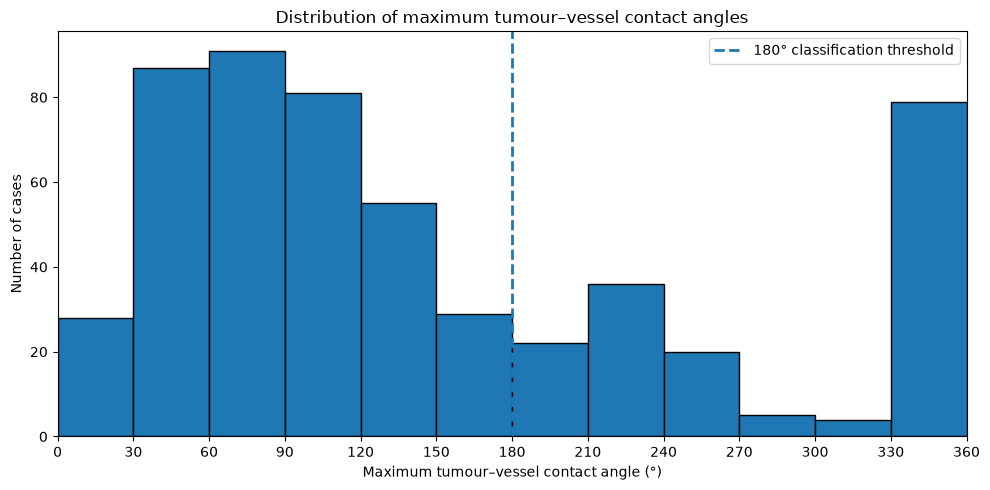

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

csv_path = (Path.cwd() / "../../src/label_derivation/derived_labels.csv").resolve()

if not csv_path.exists():
    raise FileNotFoundError(f"Can;t find: {csv_path}")

df = pd.read_csv(csv_path)

df_contact = df[df["overall_max_angle"] > 0]

bins = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360]

plt.figure(figsize=(10, 5))

plt.hist(
    df_contact["overall_max_angle"],
    bins=bins,
    edgecolor="black"
)

plt.axvline(
    180,
    linestyle="--",
    linewidth=2,
    label="180° classification threshold"
)

plt.xlabel("Maximum tumour–vessel contact angle (°)")
plt.ylabel("Number of cases")
plt.title("Distribution of maximum tumour–vessel contact angles")

plt.xticks(bins)
plt.xlim(0, 360)
plt.legend()

plt.tight_layout()
plt.show()

In [3]:
bins = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 361]

df_contact = df[df["overall_max_angle"] > 0]

binned = pd.cut(
    df_contact["overall_max_angle"],
    bins=bins,
    right=False
)

binned.value_counts().sort_index()

overall_max_angle
[0, 30)       28
[30, 60)      87
[60, 90)      91
[90, 120)     81
[120, 150)    55
[150, 180)    29
[180, 210)    22
[210, 240)    36
[240, 270)    20
[270, 300)     5
[300, 330)     4
[330, 361)    79
Name: count, dtype: int64

### Check for the 165 vs 166 discrepancy: cases with angle exactly at/near 180

In [11]:
exact_180 = df[df["overall_max_angle"] == 180.0]
near_180 = df[(df["overall_max_angle"] >= 179.9) & (df["overall_max_angle"] <= 180.1)]

print(f"exactly 180.0: {len(exact_180)}")
print(exact_180[["case_id", "overall_max_angle", "derived_label"]])

print(f"\noverall_max_angle within 179.9-180.1: {len(near_180)}")
print(near_180[["case_id", "overall_max_angle", "derived_label"]])

n_label_high = (df["derived_label"] == "high_vascular_contact").sum()
n_angle_ge_180 = (df["overall_max_angle"] >= 180).sum()
n_angle_gt_180 = (df["overall_max_angle"] > 180).sum()

print(f"\nLabel ==> high_vascular_contact: {n_label_high}")
print(f"overall_max_angle >= 180: {n_angle_ge_180}")
print(f"overall_max_angle > 180: {n_angle_gt_180}")

exactly 180.0: 1
            case_id  overall_max_angle         derived_label
131  PanTS_00001873              180.0  low_vascular_contact

overall_max_angle within 179.9-180.1: 1
            case_id  overall_max_angle         derived_label
131  PanTS_00001873              180.0  low_vascular_contact

Label ==> high_vascular_contact: 165
overall_max_angle >= 180: 166
overall_max_angle > 180: 165


In [7]:
n_le_180 = (df_contact["overall_max_angle"] <= 180).sum()
n_gt_180 = (df_contact["overall_max_angle"] > 180).sum()

print(f"<=180: {n_le_180}")
print(f">180: {n_gt_180}")
print(f"sum: {n_le_180 + n_gt_180}")
print(f"total non-zero cases: {len(df_contact)}")

<=180: 372
>180: 165
sum: 537
total non-zero cases: 537


In [ ]:
df_contact = df[df["overall_max_angle"] > 0]

vessel_counts = df_contact["driving_vessel"].value_counts()
print(vessel_counts)

vessel_pct = (vessel_counts / len(df_contact) * 100).round(1)
print(vessel_pct)

driving_vessel
veins       394
ca           72
postcava     37
sma          31
aorta         3
Name: count, dtype: int64
driving_vessel
veins       73.4
ca          13.4
postcava     6.9
sma          5.8
aorta        0.6
Name: count, dtype: float64
